# Wykres rozkładu zmiennej według kategorii

Notebook prezentuje wykres porównujący rozkład wybranej zmiennej liczbowej w podziale na kategorie. Dla każdej kategorii pokazujemy minimum, maksimum, kwartyle (P25 i P75), medianę oraz średnią.

## Interpretacja elementów wykresu
- **Cienka linia i zakończenia:** minimum–maksimum.
- **Grubsza linia:** przedział międzykwartylowy P25–P75.
- **Zielone koło:** mediana.
- **Pomarańczowy romb:** średnia.


## 1. Przygotowanie danych

Tworzymy deterministyczny, przykładowy zbiór 100 pracowników. Dane są syntetyczne.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

stanowiska = np.repeat(
    ["Analityk", "Doradca", "Kasjer", "Specjalista"], [25, 25, 25, 25]
)

parametry_wieku = {
    "Analityk": (34, 6),
    "Doradca": (39, 8),
    "Kasjer": (43, 9),
    "Specjalista": (32, 5),
}

wiek = np.concatenate(
    [
        rng.normal(*parametry_wieku[stanowisko], size=25)
        for stanowisko in parametry_wieku
    ]
)

df = pd.DataFrame(
    {
        "Stanowisko": stanowiska,
        "Wiek": np.clip(wiek, 20, 65).round(1),
        "Staz_lata": rng.integers(0, 25, size=100),
    }
)

df.head()

,Stanowisko,Wiek,Staz_lata
0,Analityk,35.8,11
1,Analityk,27.8,6
2,Analityk,38.5,19
3,Analityk,39.6,24
4,Analityk,22.3,6


## 2. Wybór zmiennej i kategorii

Wystarczy zmienić wartości `kolumna` i `kategoria`, aby wykorzystać wykres dla innej zmiennej liczbowej lub podziału.

In [2]:
kolumna = "Wiek"
kategoria = "Stanowisko"

# Statystyki dla każdej kategorii
stats = (
    df.groupby(kategoria)[kolumna]
    .agg(
        minimum="min",
        p25=lambda x: x.quantile(0.25),
        mediana="median",
        srednia="mean",
        p75=lambda x: x.quantile(0.75),
        maksimum="max",
    )
    .sort_values("mediana")
)

stats

,minimum,p25,mediana,srednia,p75,maksimum
Stanowisko,,,,,,
Specjalista,23.6,28.7,30.5,30.740,34.2,35.5
Analityk,22.3,29.9,33.9,33.788,38.5,41.3
Kasjer,27.9,37.3,40.5,41.840,48.3,56.5
Doradca,32.3,36.2,40.9,40.732,43.9,56.1


## 3. Wykres

Wykres zachowuje wspólną skalę osi X dla wszystkich kategorii. Tytuł jest centrowany względem całej figury, a legenda znajduje się pod wykresem.

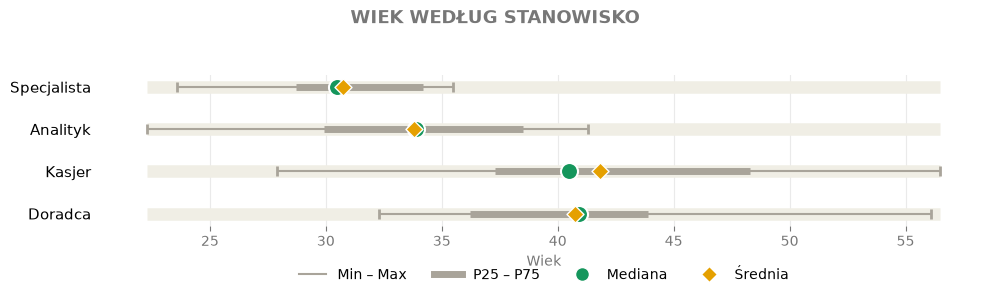

In [3]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, max(3.5, len(stats) * 0.8)))

y = np.arange(len(stats))
xmin = stats["minimum"].min()
xmax = stats["maksimum"].max()
data_range = xmax - xmin
margin = data_range * 0.05 if data_range > 0 else 1

# Jasne tło – wspólny zakres obserwacji
ax.hlines(y, xmin, xmax, color="#F0EEE5", linewidth=9, zorder=1)

# Min–Max
ax.hlines(
    y, stats["minimum"], stats["maksimum"], color="#A9A49A", linewidth=1.5, zorder=2
)
ax.vlines(stats["minimum"], y - 0.12, y + 0.12, color="#A9A49A", linewidth=2, zorder=2)
ax.vlines(stats["maksimum"], y - 0.12, y + 0.12, color="#A9A49A", linewidth=2, zorder=2)

# Przedział międzykwartylowy P25–P75
ax.hlines(y, stats["p25"], stats["p75"], color="#A9A49A", linewidth=5, zorder=3)

# Mediana
ax.scatter(
    stats["mediana"],
    y,
    color="#15965C",
    s=150,
    edgecolors="white",
    linewidths=1.5,
    zorder=4,
)

# Średnia
ax.scatter(
    stats["srednia"],
    y,
    color="#E5A000",
    marker="D",
    s=75,
    edgecolors="white",
    linewidths=1,
    zorder=5,
)

# Legenda
legend = [
    Line2D([0], [0], color="#A9A49A", linewidth=1.5, label="Min – Max"),
    Line2D([0], [0], color="#A9A49A", linewidth=5, label="P25 – P75"),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#15965C",
        markersize=10,
        label="Mediana",
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        color="w",
        markerfacecolor="#E5A000",
        markersize=8,
        label="Średnia",
    ),
]

ax.legend(
    handles=legend,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=4,
    frameon=False,
)

# Tytuł centrowany względem całej figury
fig.suptitle(
    f"{kolumna.upper()} WEDŁUG {kategoria.upper()}",
    fontsize=13,
    fontweight="bold",
    color="#777777",
    y=0.98,
)

# Osie i formatowanie
ax.set_yticks(y)
ax.set_yticklabels(stats.index, fontsize=11)
ax.invert_yaxis()
ax.set_xlim(xmin - margin, xmax + margin)
ax.set_xlabel(kolumna, fontsize=10, color="#777777")
ax.tick_params(axis="x", labelsize=10, colors="#777777")
ax.tick_params(axis="y", length=0, pad=12)
ax.grid(axis="x", color="#EAEAEA", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")
fig.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()